In [5]:
"""
=========================================================================
 MODELING: LOGISTIC REGRESSION (17 FITUR - BEBAS MULTIKOL & VARIANS NOL)
 Deteksi Phishing Berbasis AI - Komparasi Model dengan Implementasi Deployment
=========================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

In [6]:
# -------------------------------------------------------------------
# 1. LOAD DATASET TRAIN & TEST (dari Google Drive)
# -------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

path_train = "/content/drive/MyDrive/dsco/train_features_20.csv"
path_test  = "/content/drive/MyDrive/dsco/test_features_20.csv"

df_train = pd.read_csv(path_train)
df_test  = pd.read_csv(path_test)

print("Ukuran data train awal:", df_train.shape)
print("Ukuran data test awal :", df_test.shape)

Mounted at /content/drive
Ukuran data train awal: (6298, 22)
Ukuran data test awal : (1575, 22)


In [7]:
# -------------------------------------------------------------------
# 2. PEMISAHAN FITUR (X) DAN LABEL (y) — 17 FITUR BERSIH
# -------------------------------------------------------------------
# Daftar 17 fitur (bebas multikolinearitas & varians nol)
fitur_17 = [
    "urllength", "dotcount", "httpsflag", "urlentropy",
    "subdomaincount", "queryparamcount", "tldlength", "pathlength",
    "hyphenindomain", "tldpopularity", "domainnamelength",
    "percentagenumericchars", "count_dashes", "count_underscores",
    "count_slashes", "count_ques", "count_non_alphanumeric"
]

# Pengaman tambahan: hanya ambil kolom yang benar-benar ada & tidak konstan
fitur_kolom = [col for col in fitur_17 if col in df_train.columns and df_train[col].nunique() > 1]

X_train = df_train[fitur_kolom]
y_train = df_train["ClassLabel"]  # 0 = Legitimate, 1 = Phishing

X_test = df_test[fitur_kolom]
y_test = df_test["ClassLabel"]

print("\nJumlah data training :", X_train.shape[0])
print("Jumlah data test      :", X_test.shape[0])
print("Jumlah fitur aktif    :", len(fitur_kolom))
print("Daftar 17 Fitur       :", fitur_kolom)


Jumlah data training : 6298
Jumlah data test      : 1575
Jumlah fitur aktif    : 17
Daftar 17 Fitur       : ['urllength', 'dotcount', 'httpsflag', 'urlentropy', 'subdomaincount', 'queryparamcount', 'tldlength', 'pathlength', 'hyphenindomain', 'tldpopularity', 'domainnamelength', 'percentagenumericchars', 'count_dashes', 'count_underscores', 'count_slashes', 'count_ques', 'count_non_alphanumeric']


In [8]:
# -------------------------------------------------------------------
# 3. STANDARDISASI FITUR
# -------------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
# -------------------------------------------------------------------
# 4. TRAINING MODEL LOGISTIC REGRESSION
# -------------------------------------------------------------------
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [10]:
# -------------------------------------------------------------------
# 5. PREDIKSI PADA DATA TEST
# -------------------------------------------------------------------
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

In [11]:
# -------------------------------------------------------------------
# 6. EVALUASI MODEL
# -------------------------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\n===== HASIL EVALUASI: LOGISTIC REGRESSION (17 FITUR) =====")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"]))


===== HASIL EVALUASI: LOGISTIC REGRESSION (17 FITUR) =====
Accuracy   : 0.9429
Precision  : 0.9698
Recall     : 0.9289
F1-Score   : 0.9489
ROC-AUC    : 0.9798

Classification Report:
                precision    recall  f1-score   support

Legitimate (0)       0.91      0.96      0.94       675
  Phishing (1)       0.97      0.93      0.95       900

      accuracy                           0.94      1575
     macro avg       0.94      0.95      0.94      1575
  weighted avg       0.94      0.94      0.94      1575



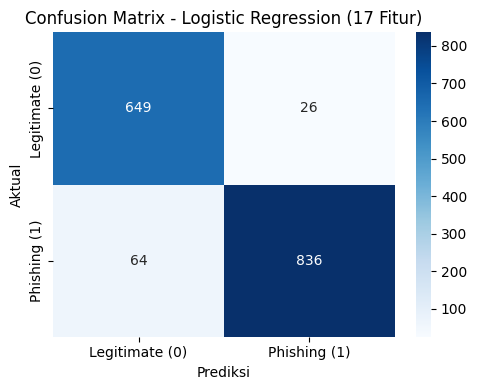

In [12]:
# -------------------------------------------------------------------
# 7. CONFUSION MATRIX
# -------------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Phishing (1)"],
    yticklabels=["Legitimate (0)", "Phishing (1)"]
)
plt.title("Confusion Matrix - Logistic Regression (17 Fitur)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.savefig("confusion_matrix_logreg_17fitur.png", dpi=200)
plt.show()

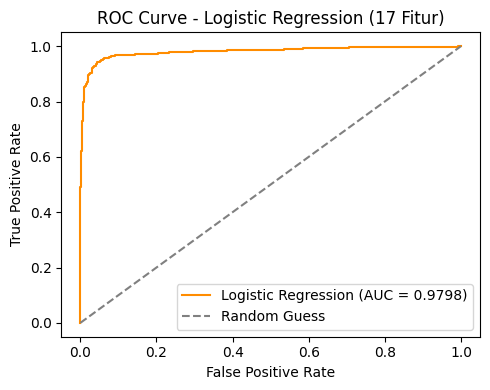

In [13]:
# -------------------------------------------------------------------
# 8. ROC CURVE
# -------------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression (17 Fitur)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve_logreg_17fitur.png", dpi=200)
plt.show()


Fitur paling berpengaruh (berdasarkan |koefisien|):
                     Fitur  Koefisien
0                urllength   3.757464
10        domainnamelength   2.990689
8           hyphenindomain   2.725280
4           subdomaincount  -2.500271
1                 dotcount   1.529885
16  count_non_alphanumeric  -1.481032
12            count_dashes  -1.358240
2                httpsflag  -1.265147
14           count_slashes   1.033018
7               pathlength   0.842760


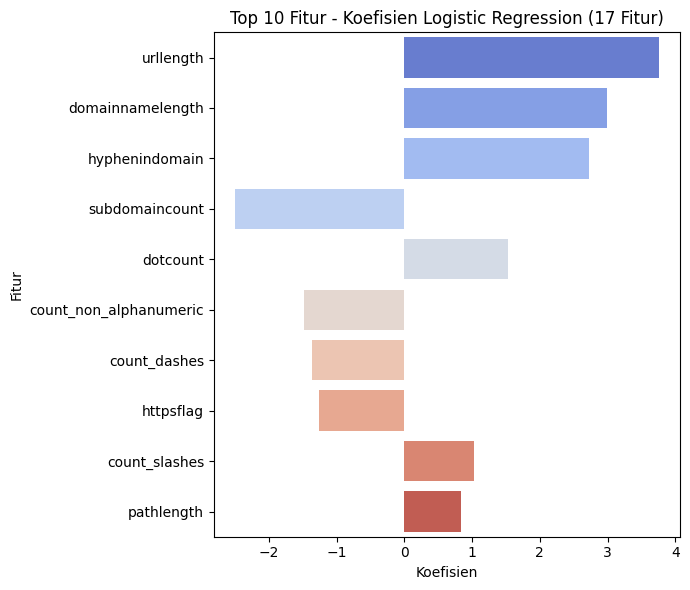

In [14]:
# -------------------------------------------------------------------
# 9. FEATURE IMPORTANCE (KOEFISIEN MODEL)
# -------------------------------------------------------------------
koef_df = pd.DataFrame({
    "Fitur": fitur_kolom,
    "Koefisien": log_reg.coef_[0]
}).sort_values(by="Koefisien", key=abs, ascending=False)

print("\nFitur paling berpengaruh (berdasarkan |koefisien|):")
print(koef_df.head(10))

plt.figure(figsize=(7, 6))
sns.barplot(data=koef_df.head(10), x="Koefisien", y="Fitur", hue="Fitur", palette="coolwarm", legend=False)
plt.title("Top 10 Fitur - Koefisien Logistic Regression (17 Fitur)")
plt.tight_layout()
plt.savefig("feature_importance_logreg_17fitur.png", dpi=200)
plt.show()

In [15]:
# -------------------------------------------------------------------
# 10. SIMPAN MODEL & SCALER UNTUK DEPLOYMENT
# -------------------------------------------------------------------
joblib.dump(log_reg, "model_logistic_regression_17fitur.pkl")
joblib.dump(scaler, "scaler_logistic_regression_17fitur.pkl")

print("\nModel dan scaler 17 fitur berhasil disimpan:")
print("- model_logistic_regression_17fitur.pkl")
print("- scaler_logistic_regression_17fitur.pkl")


Model dan scaler 17 fitur berhasil disimpan:
- model_logistic_regression_17fitur.pkl
- scaler_logistic_regression_17fitur.pkl


In [16]:
# -------------------------------------------------------------------
# 11. EKSTRAKSI PERSAMAAN MATEMATIKA (LOGIT z)
# -------------------------------------------------------------------
intercept = log_reg.intercept_[0]
coefficients = log_reg.coef_[0]

df_rumus = pd.DataFrame(
    {"Fitur": fitur_kolom, "Koefisien_Beta": coefficients}
).sort_values(by="Koefisien_Beta", key=abs, ascending=False)

print("\n=== PARAMETER MODEL LOGISTIC REGRESSION (17 FITUR) ===")
print(f"Intercept (Beta_0) : {intercept:.6f}\n")
print("Tabel Koefisien Fitur (Urut berdasarkan pengaruh terbesar):")
print(df_rumus.to_string(index=False))

suku_persamaan = [
    f"({coef:+.4f} * {col}_scaled)"
    for col, coef in zip(fitur_kolom, coefficients)
]
persamaan_z = f"z = {intercept:.4f}\n    " + "\n    ".join(suku_persamaan)

print("\n=== PERSAMAAN RUMUS LOGIT (z) ===")
print(persamaan_z)
print("\nRumus Akhir Probabilitas:")
print("P(Phishing) = 1 / (1 + exp(-z))")


=== PARAMETER MODEL LOGISTIC REGRESSION (17 FITUR) ===
Intercept (Beta_0) : 2.704493

Tabel Koefisien Fitur (Urut berdasarkan pengaruh terbesar):
                 Fitur  Koefisien_Beta
             urllength        3.757464
      domainnamelength        2.990689
        hyphenindomain        2.725280
        subdomaincount       -2.500271
              dotcount        1.529885
count_non_alphanumeric       -1.481032
          count_dashes       -1.358240
             httpsflag       -1.265147
         count_slashes        1.033018
            pathlength        0.842760
         tldpopularity       -0.645293
percentagenumericchars       -0.568823
             tldlength       -0.543830
            urlentropy       -0.400785
       queryparamcount       -0.262213
     count_underscores       -0.108890
            count_ques        0.098676

=== PERSAMAAN RUMUS LOGIT (z) ===
z = 2.7045
    (+3.7575 * urllength_scaled)
    (+1.5299 * dotcount_scaled)
    (-1.2651 * httpsflag_scaled)
    (-0

In [17]:
# -------------------------------------------------------------------
# 12. VERIFIKASI PERHITUNGAN MANUAL VS SKLEARN
# -------------------------------------------------------------------
sampel_x = X_test_scaled[0]
z_manual = intercept + np.dot(sampel_x, coefficients)
prob_manual = 1 / (1 + np.exp(-z_manual))
prob_sklearn = log_reg.predict_proba(sampel_x.reshape(1, -1))[0][1]

print("\n=== VERIFIKASI PERHITUNGAN MANUAL (Sampel Data Uji #1) ===")
print(f"Nilai z (Logit)          : {z_manual:.6f}")
print(f"Probabilitas Manual      : {prob_manual:.6f}")
print(f"Probabilitas Scikit-Learn: {prob_sklearn:.6f}")


=== VERIFIKASI PERHITUNGAN MANUAL (Sampel Data Uji #1) ===
Nilai z (Logit)          : -1.028126
Probabilitas Manual      : 0.263448
Probabilitas Scikit-Learn: 0.263448
